In [6]:
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split, StratifiedKFold, cross_val_score
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier, GradientBoostingClassifier
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score, f1_score, roc_auc_score,
    confusion_matrix, classification_report, ConfusionMatrixDisplay, roc_curve,
)

In [7]:
CSV_PATH = "bank.csv"
OUTPUT_TARGET = "bank_data_target.csv"
RANDOM_STATE = 42
TEST_SIZE = 0.2
BUANG_DURATION = True

In [8]:
print("=" * 70)
print("1. LOAD DATA")
print("=" * 70)
if not os.path.exists(CSV_PATH):
    raise FileNotFoundError(
        f"File '{CSV_PATH}' tidak ditemukan. Taruh di folder yang sama "
        "dengan script ini, atau ubah CSV_PATH."
    )

df = pd.read_csv(CSV_PATH)
print("Ukuran data :", df.shape)
print("Missing value (total):", int(df.isna().sum().sum()))
print("Data duplikat        :", int(df.duplicated().sum()))
print("\n5 baris pertama:")
print(df.head().to_string())

1. LOAD DATA
Ukuran data : (11162, 17)
Missing value (total): 0
Data duplikat        : 0

5 baris pertama:
   age         job  marital  education default  balance housing loan  contact  day month  duration  campaign  pdays  previous poutcome deposit
0   59      admin.  married  secondary      no     2343     yes   no  unknown    5   may      1042         1     -1         0  unknown     yes
1   56      admin.  married  secondary      no       45      no   no  unknown    5   may      1467         1     -1         0  unknown     yes
2   41  technician  married  secondary      no     1270     yes   no  unknown    5   may      1389         1     -1         0  unknown     yes
3   55    services  married  secondary      no     2476     yes   no  unknown    5   may       579         1     -1         0  unknown     yes
4   54      admin.  married   tertiary      no      184      no   no  unknown    5   may       673         2     -1         0  unknown     yes


In [9]:
df["target"] = (df["deposit"].str.strip().str.lower() == "yes").astype(int)

print("\n" + "=" * 70)
print("2. TARGET BINER")
print("=" * 70)
dist = df["target"].value_counts().sort_index()
print(f"Kelas 0 (no)  : {dist[0]} ({dist[0] / len(df):.1%})")
print(f"Kelas 1 (yes) : {dist[1]} ({dist[1] / len(df):.1%})")

# Simpan data target (fitur + label biner)
df.drop(columns=["deposit"]).to_csv(OUTPUT_TARGET, index=False, encoding="utf-8-sig")
print(f"[OK] Data target disimpan ke: {OUTPUT_TARGET}")


2. TARGET BINER
Kelas 0 (no)  : 5873 (52.6%)
Kelas 1 (yes) : 5289 (47.4%)
[OK] Data target disimpan ke: bank_data_target.csv


In [10]:
X = df.drop(columns=["deposit", "target"])
y = df["target"]
if BUANG_DURATION:
    X = X.drop(columns=["duration"])

kolom_num = X.select_dtypes(include="number").columns.tolist()
kolom_kat = [c for c in X.columns if c not in kolom_num]
print("\nFitur numerik   :", kolom_num)
print("Fitur kategorik :", kolom_kat)

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=TEST_SIZE, random_state=RANDOM_STATE, stratify=y
)
print(f"\nData latih: {X_train.shape} | Data uji: {X_test.shape}")

preprocess = ColumnTransformer([
    ("num", StandardScaler(), kolom_num),
    ("cat", OneHotEncoder(handle_unknown="ignore"), kolom_kat),
])


Fitur numerik   : ['age', 'balance', 'day', 'campaign', 'pdays', 'previous']
Fitur kategorik : ['job', 'marital', 'education', 'default', 'housing', 'loan', 'contact', 'month', 'poutcome']



Data latih: (8929, 15) | Data uji: (2233, 15)


In [11]:
models = {
    "Logistic Regression": LogisticRegression(max_iter=2000),
    "Decision Tree": DecisionTreeClassifier(max_depth=6, random_state=RANDOM_STATE),
    "Random Forest": RandomForestClassifier(
        n_estimators=300, random_state=RANDOM_STATE, n_jobs=-1
    ),
    "Gradient Boosting": GradientBoostingClassifier(random_state=RANDOM_STATE),
}

pipelines = {n: Pipeline([("prep", preprocess), ("clf", m)]) for n, m in models.items()}

print("\n" + "=" * 70)
print("3. PELATIHAN & EVALUASI")
print("=" * 70)

skf = StratifiedKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)
baris = []
prediksi = {}
proba = {}

for nama, pipe in pipelines.items():
    print(f"Melatih {nama} ...")
    pipe.fit(X_train, y_train)
    y_pred = pipe.predict(X_test)
    y_prob = pipe.predict_proba(X_test)[:, 1]
    prediksi[nama], proba[nama] = y_pred, y_prob

    cv = cross_val_score(pipe, X_train, y_train, cv=skf, scoring="f1", n_jobs=-1)
    baris.append({
        "Model": nama,
        "Accuracy": accuracy_score(y_test, y_pred),
        "Precision": precision_score(y_test, y_pred),
        "Recall": recall_score(y_test, y_pred),
        "F1-Score": f1_score(y_test, y_pred),
        "ROC-AUC": roc_auc_score(y_test, y_prob),
        "CV F1 (5-fold)": cv.mean(),
    })

hasil = pd.DataFrame(baris).set_index("Model").round(4)
print("\nPerbandingan model (data uji):")
print(hasil.to_string())

model_terbaik = hasil["F1-Score"].idxmax()
print(f"\nModel terbaik (F1-Score): {model_terbaik}")
print("\nClassification report:")
print(classification_report(
    y_test, prediksi[model_terbaik], target_names=["no (0)", "yes (1)"]
))
cm = confusion_matrix(y_test, prediksi[model_terbaik])
print("Confusion matrix:\n", cm)


3. PELATIHAN & EVALUASI
Melatih Logistic Regression ...
Melatih Decision Tree ...
Melatih Random Forest ...
Melatih Gradient Boosting ...

Perbandingan model (data uji):
                     Accuracy  Precision  Recall  F1-Score  ROC-AUC  CV F1 (5-fold)
Model                                                                              
Logistic Regression    0.6955     0.7328  0.5624    0.6364   0.7579          0.6501
Decision Tree          0.6892     0.7578  0.5057    0.6066   0.7394          0.6055
Random Forest          0.7241     0.7494  0.6276    0.6831   0.7795          0.6898
Gradient Boosting      0.7407     0.7990  0.6049    0.6885   0.7934          0.6856

Model terbaik (F1-Score): Gradient Boosting

Classification report:
              precision    recall  f1-score   support

      no (0)       0.71      0.86      0.78      1175
     yes (1)       0.80      0.60      0.69      1058

    accuracy                           0.74      2233
   macro avg       0.75      0.73     


[OK] Grafik disimpan ke: hasil_klasifikasi_bank.png

10 fitur terpenting (Random Forest):
num__balance             0.1517
num__age                 0.1318
num__day                 0.1170
num__campaign            0.0648
num__pdays               0.0402
cat__poutcome_success    0.0334
cat__contact_unknown     0.0251
num__previous            0.0246
cat__contact_cellular    0.0192
cat__housing_no          0.0171
[OK] Grafik disimpan ke: fitur_penting_bank.png


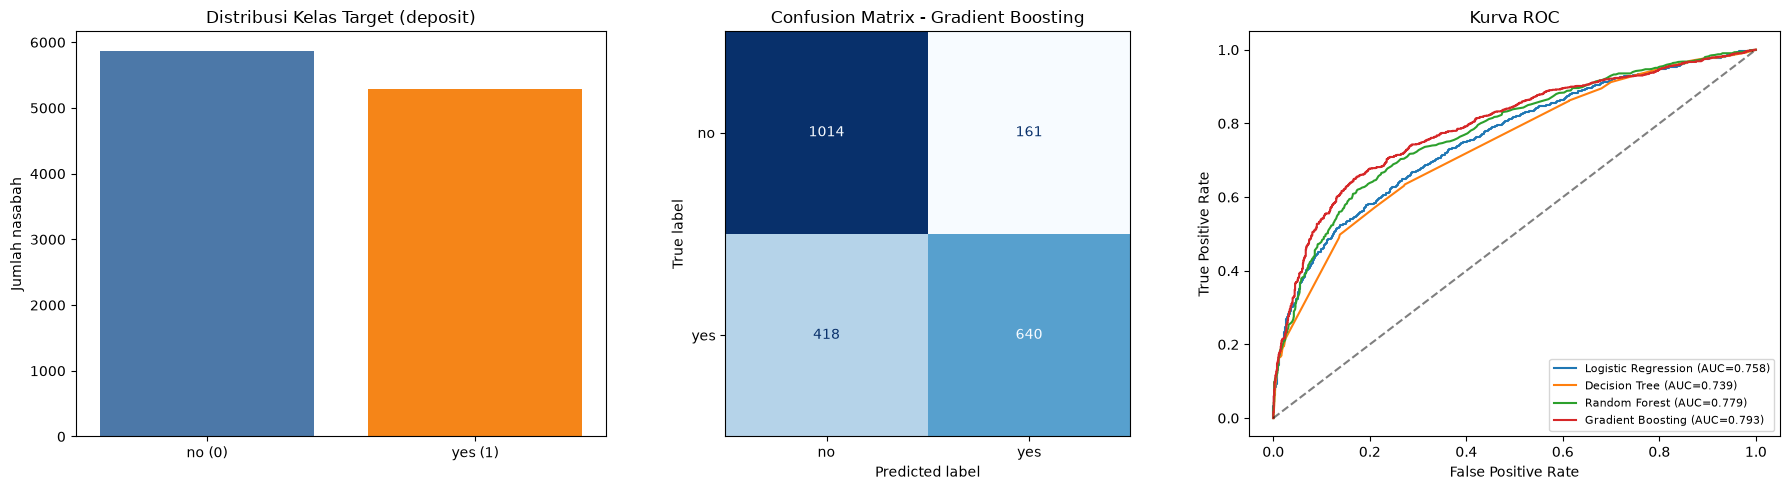

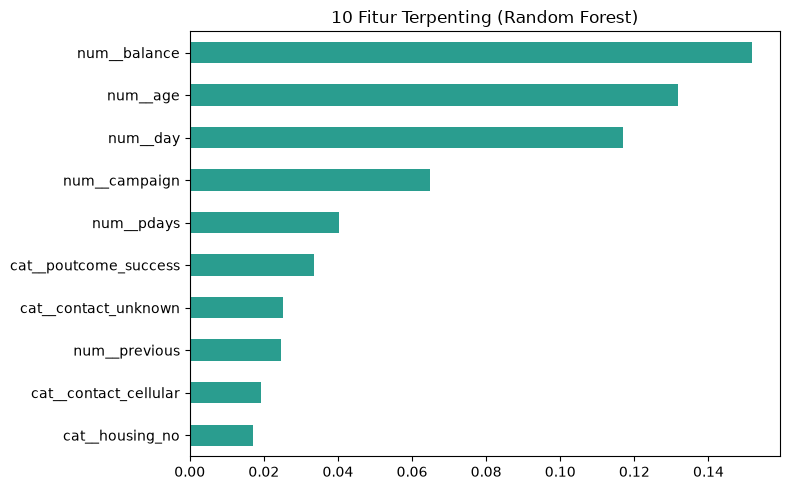

In [12]:
fig, ax = plt.subplots(1, 3, figsize=(18, 5))

# a. Distribusi target
ax[0].bar(["no (0)", "yes (1)"], dist.values, color=["#4c78a8", "#f58518"])
ax[0].set_title("Distribusi Kelas Target (deposit)")
ax[0].set_ylabel("Jumlah nasabah")

# b. Confusion matrix
ConfusionMatrixDisplay(cm, display_labels=["no", "yes"]).plot(
    ax=ax[1], cmap="Blues", colorbar=False
)
ax[1].set_title(f"Confusion Matrix - {model_terbaik}")

# c. Kurva ROC semua model
for nama, p in proba.items():
    fpr, tpr, _ = roc_curve(y_test, p)
    ax[2].plot(fpr, tpr, label=f"{nama} (AUC={roc_auc_score(y_test, p):.3f})")
ax[2].plot([0, 1], [0, 1], "k--", alpha=0.5)
ax[2].set_title("Kurva ROC")
ax[2].set_xlabel("False Positive Rate")
ax[2].set_ylabel("True Positive Rate")
ax[2].legend(loc="lower right", fontsize=8)

plt.tight_layout()
plt.savefig("hasil_klasifikasi_bank.png", dpi=150)
print("\n[OK] Grafik disimpan ke: hasil_klasifikasi_bank.png")

# Fitur terpenting (Random Forest)
rf = pipelines["Random Forest"]
nama_fitur = rf.named_steps["prep"].get_feature_names_out()
imp = pd.Series(rf.named_steps["clf"].feature_importances_, index=nama_fitur)
top = imp.sort_values(ascending=False).head(10)
print("\n10 fitur terpenting (Random Forest):")
print(top.round(4).to_string())

plt.figure(figsize=(8, 5))
top.sort_values().plot(kind="barh", color="#2a9d8f")
plt.title("10 Fitur Terpenting (Random Forest)")
plt.tight_layout()
plt.savefig("fitur_penting_bank.png", dpi=150)
print("[OK] Grafik disimpan ke: fitur_penting_bank.png")
plt.show()

In [13]:
print("\n" + "=" * 70)
print("4. CONTOH PREDIKSI")
print("=" * 70)

nasabah_baru = pd.DataFrame([{
    "age": 35, "job": "management", "marital": "married", "education": "tertiary",
    "default": "no", "balance": 2500, "housing": "no", "loan": "no",
    "contact": "cellular", "day": 15, "month": "may", "duration": 300,
    "campaign": 2, "pdays": -1, "previous": 0, "poutcome": "unknown",
}])
nasabah_baru = nasabah_baru[X.columns]  # samakan kolom (duration ikut dibuang bila perlu)

best = pipelines[model_terbaik]
p = best.predict_proba(nasabah_baru)[0, 1]
print(f"Probabilitas berlangganan deposito: {p:.2%}")
print("Prediksi:", "YES (1) - berlangganan" if p >= 0.5 else "NO (0) - tidak berlangganan")


4. CONTOH PREDIKSI
Probabilitas berlangganan deposito: 54.56%
Prediksi: YES (1) - berlangganan
